## 1. Imports & Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, StackingClassifier
)
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelweight'] = 'bold'

RANDOM_STATE = 42
CV_FOLDS = 5

print("Setup done.")

# Global Matplotlib Settings for rules.md compliance
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 15


Setup done.


## 2. Load Dataset

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='Diagnosis')   # 0 = Malignant, 1 = Benign

df = pd.concat([X, y], axis=1)

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"\nClass distribution:\n{y.value_counts()}")
df.head()

Shape: 569 rows x 31 columns
Missing values: 0

Class distribution:
Diagnosis
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Quick EDA


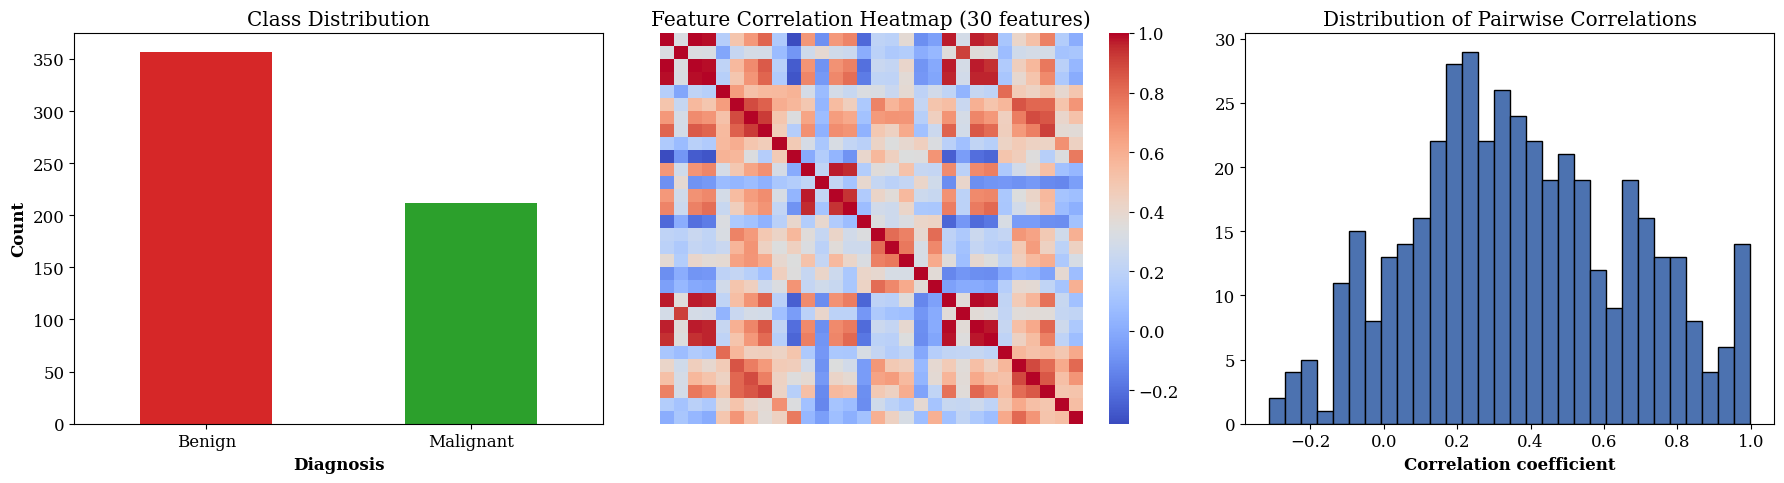

Feature pairs with |correlation| > 0.9: 42
A lot of overlap between features -> good candidate for PCA.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

y.value_counts().rename({0: 'Malignant', 1: 'Benign'}).plot(kind='bar', ax=axes[0], color=['#d62728', '#2ca02c'])
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

corr = X.corr()
sns.heatmap(corr, ax=axes[1], cmap='coolwarm', cbar=True, xticklabels=False, yticklabels=False)
axes[1].set_title('Feature Correlation Heatmap (30 features)')

high_corr_pairs = (corr.abs() > 0.9).sum().sum() - len(corr)
axes[2].hist(corr.values[np.triu_indices_from(corr.values, k=1)], bins=30, color='#4c72b0', edgecolor='black')
axes[2].set_title('Distribution of Pairwise Correlations')
axes[2].set_xlabel('Correlation coefficient')

plt.tight_layout()
plt.show()

print(f"Feature pairs with |correlation| > 0.9: {high_corr_pairs}")
print("A lot of overlap between features -> good candidate for PCA.")

# rules.md compliant consolidated 12-subplot EDA figure (Times New Roman 15pt, bold labels, 600 DPI EPS)
def plot_12_subplots_eda_v2(df, target_col='Diagnosis', save_prefix='exp7_eda_12_subplots'):
    fig, axes = plt.subplots(3, 4, figsize=(22, 16))
    plt.subplots_adjust(wspace=0.35, hspace=0.45)
    
    font_title = {'fontname': 'Times New Roman', 'fontsize': 15, 'weight': 'bold'}
    font_label = {'fontname': 'Times New Roman', 'fontsize': 15, 'weight': 'bold'}

    counts = df[target_col].value_counts()
    axes[0, 0].bar(['Benign (1)', 'Malignant (0)'], counts.values, color=['#2ca02c', '#d62728'], edgecolor='black')
    axes[0, 0].set_title('1. Target Class Distribution', **font_title)
    axes[0, 0].set_xlabel('Diagnosis Class', **font_label)
    axes[0, 0].set_ylabel('Count', **font_label)

    missing = df.isnull().sum()
    axes[0, 1].bar(range(len(missing)), missing.values, color='#1f77b4', edgecolor='black')
    axes[0, 1].set_title('2. Missing Value Count', **font_title)
    axes[0, 1].set_xlabel('Feature Index', **font_label)
    axes[0, 1].set_ylabel('Missing Count', **font_label)
    axes[0, 1].set_ylim(0, 10)

    duplicates = df.duplicated().sum()
    axes[0, 2].pie([len(df) - duplicates, max(duplicates, 1)], labels=['Unique', 'Duplicate'],
                   autopct='%1.1f%%', colors=['#4c72b0', '#c44e52'], textprops={'fontsize': 13, 'fontname': 'Times New Roman'})
    axes[0, 2].set_title('3. Duplicate Row Distribution', **font_title)

    num_df = df.select_dtypes(include=np.number)
    corr = num_df.iloc[:, :8].corr()
    sns.heatmap(corr, ax=axes[0, 3], cmap='coolwarm', cbar=False, annot=False, rasterized=True)
    axes[0, 3].set_title('4. Correlation Heatmap (8 Feat)', **font_title)
    axes[0, 3].set_xlabel('Features', **font_label)
    axes[0, 3].set_ylabel('Features', **font_label)

    sns.histplot(data=df, x='mean radius', hue=target_col, kde=True, ax=axes[1, 0], palette=['#d62728', '#2ca02c'])
    axes[1, 0].set_title('5. Mean Radius Distribution', **font_title)
    axes[1, 0].set_xlabel('Mean Radius', **font_label)
    axes[1, 0].set_ylabel('Frequency', **font_label)

    sns.histplot(data=df, x='mean texture', hue=target_col, kde=True, ax=axes[1, 1], palette=['#d62728', '#2ca02c'])
    axes[1, 1].set_title('6. Mean Texture Distribution', **font_title)
    axes[1, 1].set_xlabel('Mean Texture', **font_label)
    axes[1, 1].set_ylabel('Frequency', **font_label)

    sns.boxplot(data=df, y='mean perimeter', x=target_col, ax=axes[1, 2], palette=['#d62728', '#2ca02c'])
    axes[1, 2].set_title('7. Mean Perimeter Outliers', **font_title)
    axes[1, 2].set_xlabel('Diagnosis Class', **font_label)
    axes[1, 2].set_ylabel('Mean Perimeter', **font_label)

    sns.boxplot(data=df, y='mean area', x=target_col, ax=axes[1, 3], palette=['#d62728', '#2ca02c'])
    axes[1, 3].set_title('8. Mean Area Outliers', **font_title)
    axes[1, 3].set_xlabel('Diagnosis Class', **font_label)
    axes[1, 3].set_ylabel('Mean Area', **font_label)

    sns.scatterplot(data=df, x='mean concavity', y='mean concave points', hue=target_col, ax=axes[2, 0], palette=['#d62728', '#2ca02c'])
    axes[2, 0].set_title('9. Concavity vs Concave Pts', **font_title)
    axes[2, 0].set_xlabel('Mean Concavity', **font_label)
    axes[2, 0].set_ylabel('Mean Concave Pts', **font_label)

    sns.histplot(data=df, x='mean smoothness', hue=target_col, kde=True, ax=axes[2, 1], palette=['#d62728', '#2ca02c'])
    axes[2, 1].set_title('10. Mean Smoothness Dist', **font_title)
    axes[2, 1].set_xlabel('Mean Smoothness', **font_label)
    axes[2, 1].set_ylabel('Frequency', **font_label)

    sns.boxplot(data=df, y='worst radius', x=target_col, ax=axes[2, 2], palette=['#d62728', '#2ca02c'])
    axes[2, 2].set_title('11. Worst Radius Outliers', **font_title)
    axes[2, 2].set_xlabel('Diagnosis Class', **font_label)
    axes[2, 2].set_ylabel('Worst Radius', **font_label)

    sns.histplot(data=df, x='worst area', hue=target_col, kde=True, ax=axes[2, 3], palette=['#d62728', '#2ca02c'])
    axes[2, 3].set_title('12. Worst Area Distribution', **font_title)
    axes[2, 3].set_xlabel('Worst Area', **font_label)
    axes[2, 3].set_ylabel('Frequency', **font_label)

    plt.tight_layout()
    fig.savefig(f"{save_prefix}.png", format='png', dpi=300, bbox_inches='tight')
    fig.savefig(f"{save_prefix}.eps", format='eps', dpi=600, bbox_inches='tight')
    plt.close()
    print(f"Saved {save_prefix}.png and {save_prefix}.eps (600 DPI)")


## 4. Train/Test Split and Standardization
80-20 stratified split, then scaling fit only on the training data to avoid leaking test-set information.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Training samples: 455, Test samples: 114


## 5. PCA
Fitting PCA on the standardized training data and choosing the number of components that explain 95% of the variance (a common default rather than an arbitrary fixed number). The scree plot below is what that choice is based on.

Components needed to explain 95% variance: 10 (out of 30 original features)
Explained variance with 10 components: 95.27%


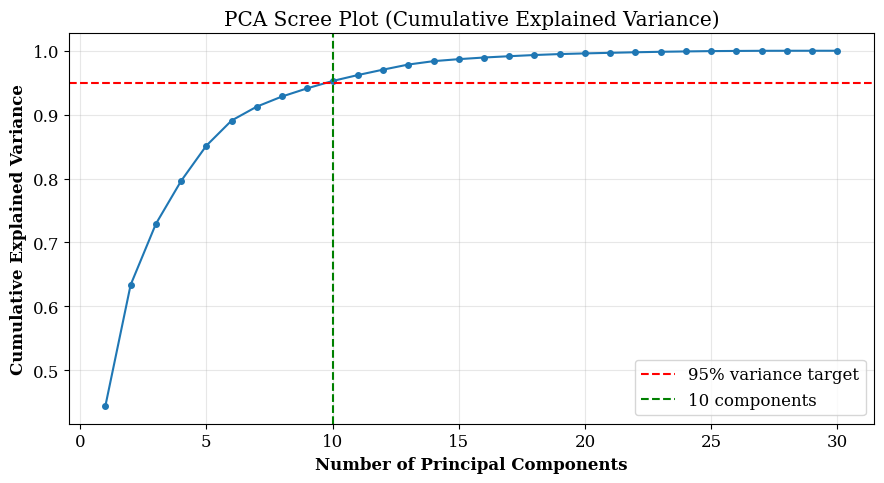

,Setting,Components Chosen,Variance Target,Explained Variance (%)
0,With-PCA,10,95%,95.27


In [5]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1

print(f"Components needed to explain 95% variance: {n_components_95} (out of {X_train_scaled.shape[1]} original features)")
print(f"Explained variance with {n_components_95} components: {cum_var[n_components_95 - 1]*100:.2f}%")

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=4)
plt.axhline(0.95, color='red', linestyle='--', label='95% variance target')
plt.axvline(n_components_95, color='green', linestyle='--', label=f'{n_components_95} components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Scree Plot (Cumulative Explained Variance)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Refit PCA with the chosen number of components
pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

pca_summary_df = pd.DataFrame({
    "Setting": ["With-PCA"],
    "Components Chosen": [n_components_95],
    "Variance Target": ["95%"],
    "Explained Variance (%)": [round(cum_var[n_components_95 - 1] * 100, 2)]
})
display(pca_summary_df)

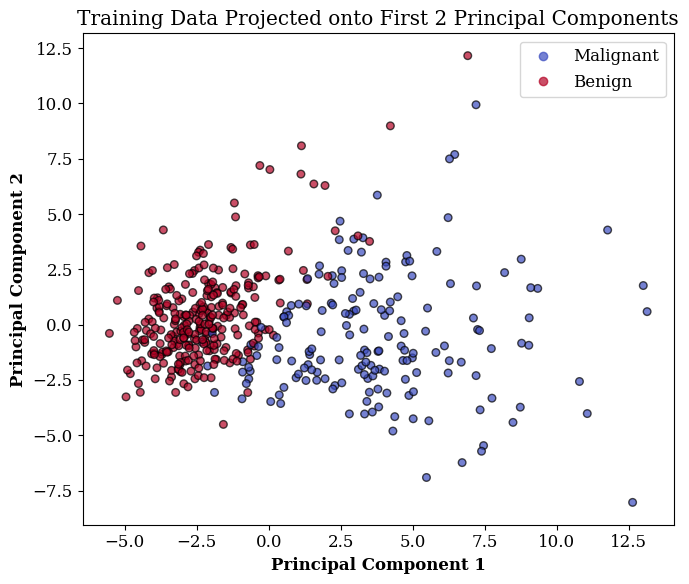

In [6]:
# 2D visual of how separable the classes already look in just the first two components
plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', alpha=0.7, edgecolor='k', s=30)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Training Data Projected onto First 2 Principal Components')
plt.legend(handles=scatter.legend_elements()[0], labels=['Malignant', 'Benign'])
plt.tight_layout()
plt.show()

## 6. Models and Hyperparameter Grids


In [7]:
def make_stacking_model():
    base_learners = [
        ("svm", make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE))),
        ("nb", GaussianNB()),
        ("dt", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]
    return StackingClassifier(
        estimators=base_learners,
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5
    )

model_configs = {
    "SVM": (
        SVC(probability=True, random_state=RANDOM_STATE),
        {"kernel": ["linear", "rbf"], "C": [0.1, 1, 10], "gamma": ["scale", "auto"]}
    ),
    "Naive Bayes": (
        GaussianNB(),
        {"var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]}
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 7, 9], "weights": ["uniform", "distance"]}
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"C": [0.01, 0.1, 1, 10], "penalty": ["l2"]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"criterion": ["gini", "entropy"], "max_depth": [3, 5, 7, None]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [100, 200], "max_depth": [5, 10, None]}
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [50, 100], "learning_rate": [0.5, 1.0]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [100, 150], "max_depth": [2, 3], "learning_rate": [0.05, 0.1]}
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
        {"n_estimators": [100, 150], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}
    ),
    "Stacking": (
        make_stacking_model(),
        {"final_estimator__C": [0.1, 1, 10]}
    ),
}

print(f"{len(model_configs)} models configured:", list(model_configs.keys()))

10 models configured: ['SVM', 'Naive Bayes', 'KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'AdaBoost', 'Gradient Boosting', 'XGBoost', 'Stacking']


## 7. Tune + Cross-Validate + Evaluate — No-PCA vs With-PCA


In [8]:
feature_sets = {
    "No-PCA": (X_train_scaled, X_test_scaled),
    "With-PCA": (X_train_pca, X_test_pca)
}

cv_strategy = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

all_results = []        # one row per (model, setting) -> test-set metrics
fold_results = []       # one row per (model, setting) -> fold-wise CV accuracy
best_params_log = {}    # model -> {setting: best_params}

for model_name, (base_model, param_grid) in model_configs.items():
    best_params_log[model_name] = {}
    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    for setting, (Xtr, Xte) in feature_sets.items():
        grid = GridSearchCV(base_model, param_grid, cv=cv_strategy, scoring="accuracy", n_jobs=-1)
        grid.fit(Xtr, y_train)
        best_model = grid.best_estimator_
        best_params_log[model_name][setting] = grid.best_params_

        # Fold-wise CV accuracy of the tuned model (for the Table 5 style comparison)
        fold_scores = cross_val_score(best_model, Xtr, y_train, cv=cv_strategy, scoring="accuracy", n_jobs=-1)
        fold_results.append([model_name, setting] + list(np.round(fold_scores, 4)) + [round(fold_scores.mean(), 4)])

        # Test-set evaluation
        y_pred = best_model.predict(Xte)
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        if hasattr(best_model, "predict_proba"):
            y_prob = best_model.predict_proba(Xte)[:, 1]
            auc = roc_auc_score(y_test, y_prob)
        else:
            auc = np.nan

        all_results.append([model_name, setting, acc, prec, rec, f1, auc])

        print(f"  [{setting:9s}] best params: {grid.best_params_}")
        print(f"  [{setting:9s}] 5-fold CV accuracy: {fold_scores.mean():.4f} (+/- {fold_scores.std():.4f})  |  Test accuracy: {acc:.4f}, F1: {f1:.4f}")

print("\nAll models tuned and evaluated under both settings.")


SVM


  [No-PCA   ] best params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
  [No-PCA   ] 5-fold CV accuracy: 0.9758 (+/- 0.0108)  |  Test accuracy: 0.9825, F1: 0.9861


  [With-PCA ] best params: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
  [With-PCA ] 5-fold CV accuracy: 0.9780 (+/- 0.0120)  |  Test accuracy: 0.9649, F1: 0.9718

Naive Bayes
  [No-PCA   ] best params: {'var_smoothing': 1e-09}
  [No-PCA   ] 5-fold CV accuracy: 0.9341 (+/- 0.0287)  |  Test accuracy: 0.9298, F1: 0.9444
  [With-PCA ] best params: {'var_smoothing': 1e-09}
  [With-PCA ] 5-fold CV accuracy: 0.9165 (+/- 0.0204)  |  Test accuracy: 0.9211, F1: 0.9379

KNN


  [No-PCA   ] best params: {'n_neighbors': 9, 'weights': 'uniform'}
  [No-PCA   ] 5-fold CV accuracy: 0.9670 (+/- 0.0155)  |  Test accuracy: 0.9737, F1: 0.9796
  [With-PCA ] best params: {'n_neighbors': 5, 'weights': 'uniform'}
  [With-PCA ] 5-fold CV accuracy: 0.9648 (+/- 0.0162)  |  Test accuracy: 0.9561, F1: 0.9655

Logistic Regression


  [No-PCA   ] best params: {'C': 0.1, 'penalty': 'l2'}
  [No-PCA   ] 5-fold CV accuracy: 0.9824 (+/- 0.0054)  |  Test accuracy: 0.9737, F1: 0.9793
  [With-PCA ] best params: {'C': 0.1, 'penalty': 'l2'}
  [With-PCA ] 5-fold CV accuracy: 0.9824 (+/- 0.0054)  |  Test accuracy: 0.9737, F1: 0.9793

Decision Tree


...

  [With-PCA ] best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 150}
  [With-PCA ] 5-fold CV accuracy: 0.9604 (+/- 0.0226)  |  Test accuracy: 0.9298, F1: 0.9444

XGBoost


  [No-PCA   ] best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
  [No-PCA   ] 5-fold CV accuracy: 0.9714 (+/- 0.0179)  |  Test accuracy: 0.9474, F1: 0.9589


  [With-PCA ] best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}
  [With-PCA ] 5-fold CV accuracy: 0.9648 (+/- 0.0162)  |  Test accuracy: 0.9386, F1: 0.9510

Stacking


  [No-PCA   ] best params: {'final_estimator__C': 10}
  [No-PCA   ] 5-fold CV accuracy: 0.9692 (+/- 0.0146)  |  Test accuracy: 0.9825, F1: 0.9861


  [With-PCA ] best params: {'final_estimator__C': 10}
  [With-PCA ] 5-fold CV accuracy: 0.9736 (+/- 0.0088)  |  Test accuracy: 0.9474, F1: 0.9577

All models tuned and evaluated under both settings.


## 8. Consolidated Results Tables

In [9]:
results_df = pd.DataFrame(all_results, columns=["Model", "Setting", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"])
print("Test-set performance, No-PCA vs With-PCA:")
display(results_df.round(4))

Test-set performance, No-PCA vs With-PCA:


,Model,Setting,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM,No-PCA,0.9825,0.9861,0.9861,0.9861,0.9937
1,SVM,With-PCA,0.9649,0.9857,0.9583,0.9718,0.9950
2,Naive Bayes,No-PCA,0.9298,0.9444,0.9444,0.9444,0.9868
3,Naive Bayes,With-PCA,0.9211,0.9315,0.9444,0.9379,0.9709
4,KNN,No-PCA,0.9737,0.9600,1.0000,0.9796,0.9944
5,KNN,With-PCA,0.9561,0.9589,0.9722,0.9655,0.9788
6,Logistic Regression,No-PCA,0.9737,0.9726,0.9861,0.9793,0.9957
7,Logistic Regression,With-PCA,0.9737,0.9726,0.9861,0.9793,0.9954
8,Decision Tree,No-PCA,0.9474,0.9459,0.9722,0.9589,0.9448
9,Decision Tree,With-PCA,0.9386,0.9577,0.9444,0.9510,0.9559


In [10]:
fold_cols = [f"Fold {i+1}" for i in range(CV_FOLDS)]
fold_df = pd.DataFrame(fold_results, columns=["Model", "Setting"] + fold_cols + ["Average"])
print("5-Fold Cross-Validation accuracy, No-PCA vs With-PCA:")
display(fold_df)

5-Fold Cross-Validation accuracy, No-PCA vs With-PCA:


,Model,Setting,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average
0,SVM,No-PCA,0.9560,0.9780,0.9780,0.9780,0.9890,0.9758
1,SVM,With-PCA,0.9560,0.9890,0.9890,0.9780,0.9780,0.9780
2,Naive Bayes,No-PCA,0.9121,0.9670,0.8901,0.9560,0.9451,0.9341
3,Naive Bayes,With-PCA,0.8791,0.9341,0.9121,0.9341,0.9231,0.9165
4,KNN,No-PCA,0.9780,0.9670,0.9560,0.9451,0.9890,0.9670
5,KNN,With-PCA,0.9560,0.9890,0.9451,0.9560,0.9780,0.9648
6,Logistic Regression,No-PCA,0.9780,0.9780,0.9890,0.9780,0.9890,0.9824
7,Logistic Regression,With-PCA,0.9780,0.9780,0.9890,0.9780,0.9890,0.9824
8,Decision Tree,No-PCA,0.9011,0.9451,0.9121,0.9341,0.9670,0.9319
9,Decision Tree,With-PCA,0.9121,0.9231,0.9231,0.9670,0.9231,0.9297


In [11]:
# Side-by-side view: one row per model, columns for No-PCA / With-PCA CV accuracy
pivot_cv = fold_df.pivot(index="Model", columns="Setting", values="Average")
pivot_cv["Improvement (With-PCA - No-PCA)"] = pivot_cv["With-PCA"] - pivot_cv["No-PCA"]
pivot_cv = pivot_cv.sort_values("Improvement (With-PCA - No-PCA)", ascending=False)
print("Which models gained or lost from PCA (based on mean 5-fold CV accuracy):")
display(pivot_cv.round(4))

Which models gained or lost from PCA (based on mean 5-fold CV accuracy):


Setting,No-PCA,With-PCA,Improvement (With-PCA - No-PCA)
Model,,,
Stacking,0.9692,0.9736,0.0044
SVM,0.9758,0.9780,0.0022
Logistic Regression,0.9824,0.9824,0.0000
Decision Tree,0.9319,0.9297,-0.0022
Random Forest,0.9626,0.9604,-0.0022
KNN,0.9670,0.9648,-0.0022
Gradient Boosting,0.9648,0.9604,-0.0044
XGBoost,0.9714,0.9648,-0.0066
AdaBoost,0.9802,0.9648,-0.0154


## 9. Visual Comparison

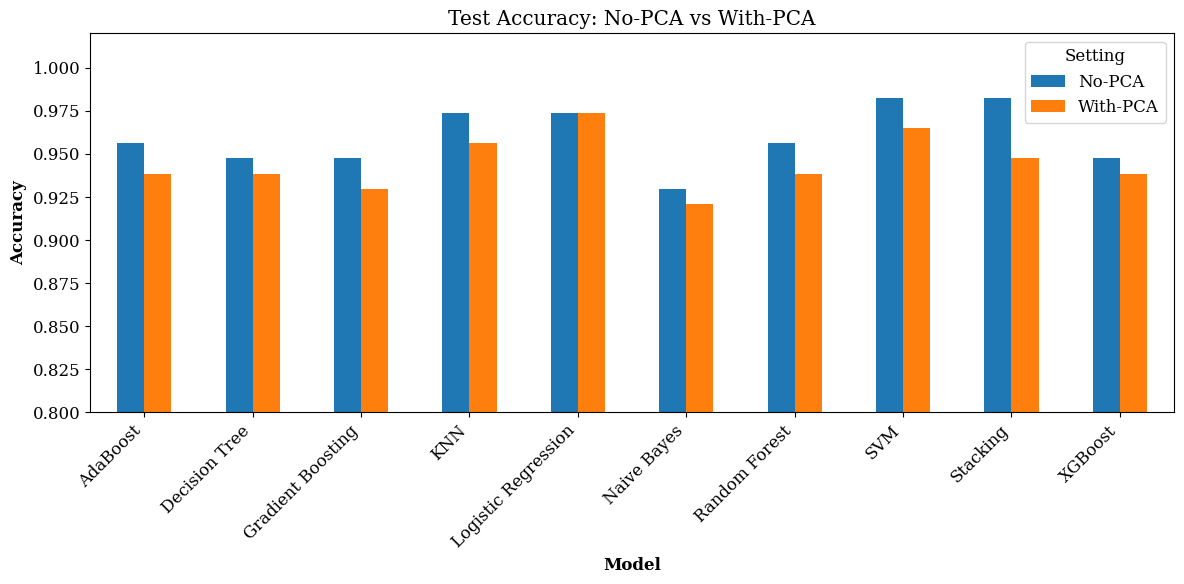

In [12]:
pivot_acc = results_df.pivot(index="Model", columns="Setting", values="Accuracy")
pivot_acc.plot(kind="bar", figsize=(12, 6), color=["#1f77b4", "#ff7f0e"])
plt.title("Test Accuracy: No-PCA vs With-PCA")
plt.ylabel("Accuracy")
plt.ylim(0.8, 1.02)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Setting")
plt.tight_layout()
plt.show()

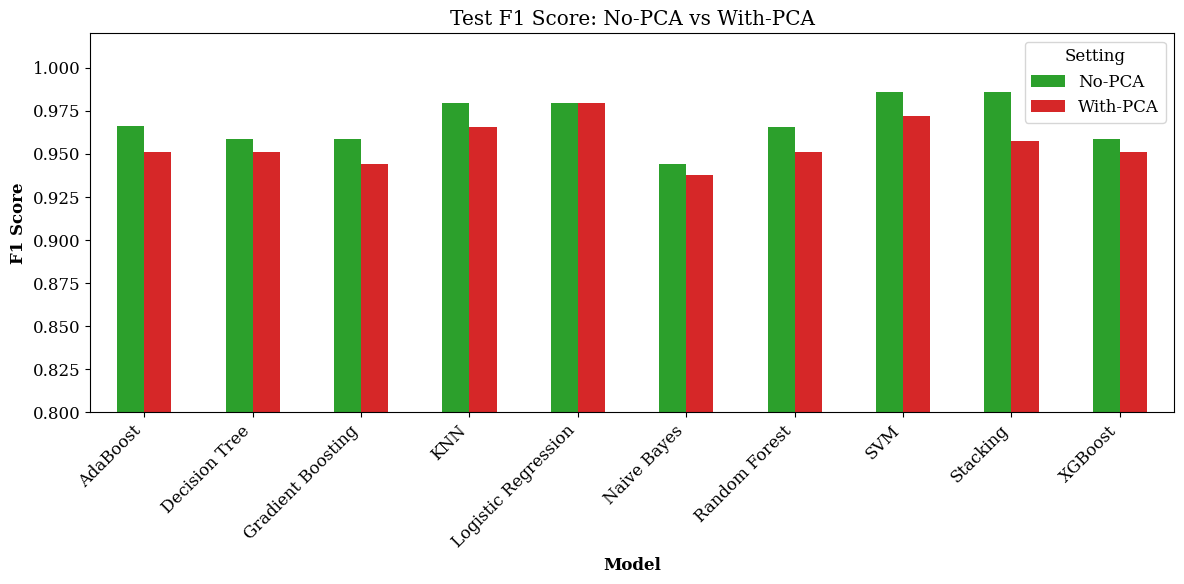

In [13]:
pivot_f1 = results_df.pivot(index="Model", columns="Setting", values="F1 Score")
pivot_f1.plot(kind="bar", figsize=(12, 6), color=["#2ca02c", "#d62728"])
plt.title("Test F1 Score: No-PCA vs With-PCA")
plt.ylabel("F1 Score")
plt.ylim(0.8, 1.02)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Setting")
plt.tight_layout()
plt.show()

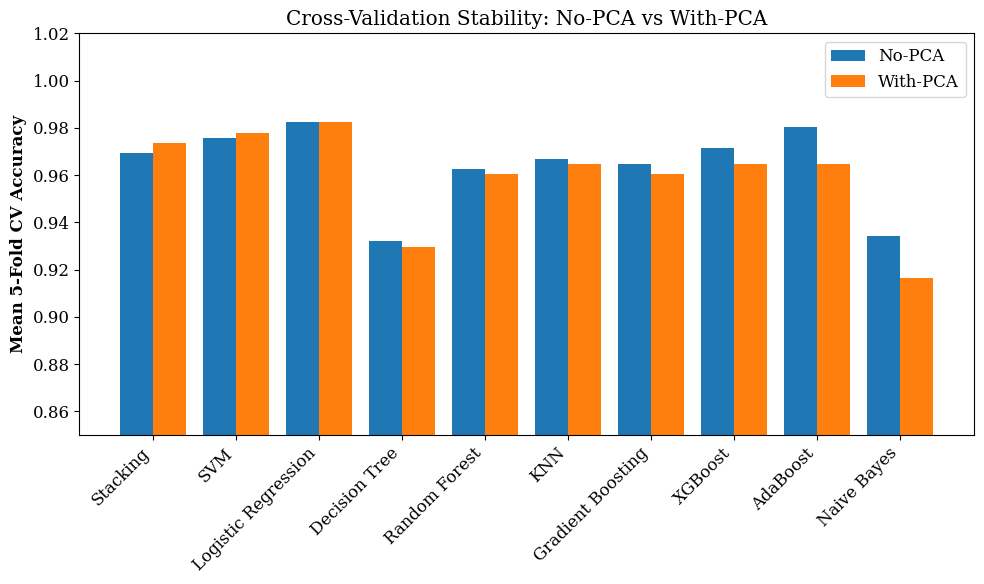

In [14]:
plt.figure(figsize=(10, 6))
x = np.arange(len(pivot_cv))
plt.bar(x - 0.2, pivot_cv["No-PCA"], width=0.4, label="No-PCA")
plt.bar(x + 0.2, pivot_cv["With-PCA"], width=0.4, label="With-PCA")
plt.xticks(x, pivot_cv.index, rotation=45, ha='right')
plt.ylabel("Mean 5-Fold CV Accuracy")
plt.title("Cross-Validation Stability: No-PCA vs With-PCA")
plt.ylim(0.85, 1.02)
plt.legend()
plt.tight_layout()
plt.show()

## 10. ROC Curves and Confusion Matrices (Selected Models)


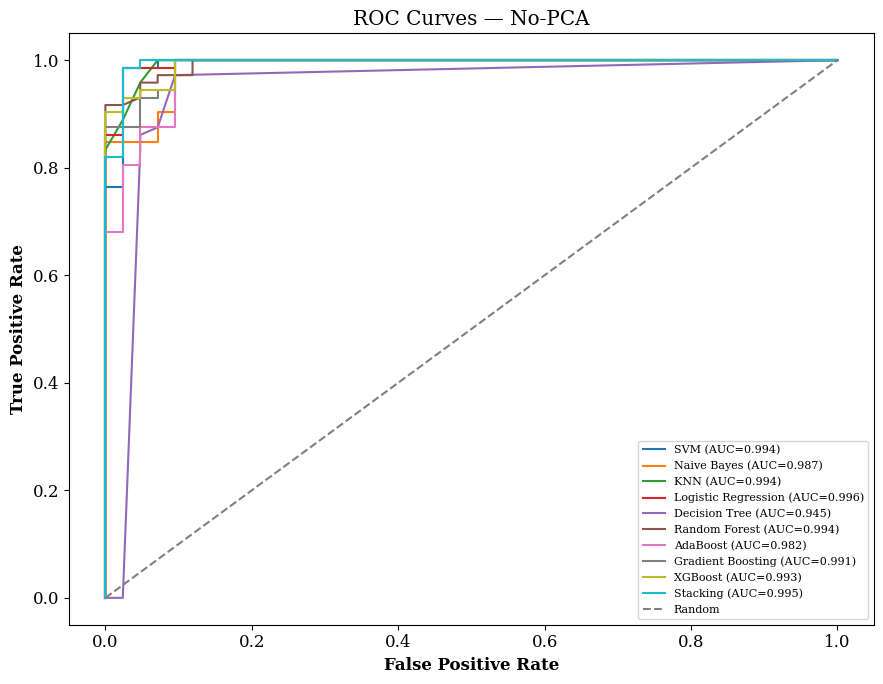

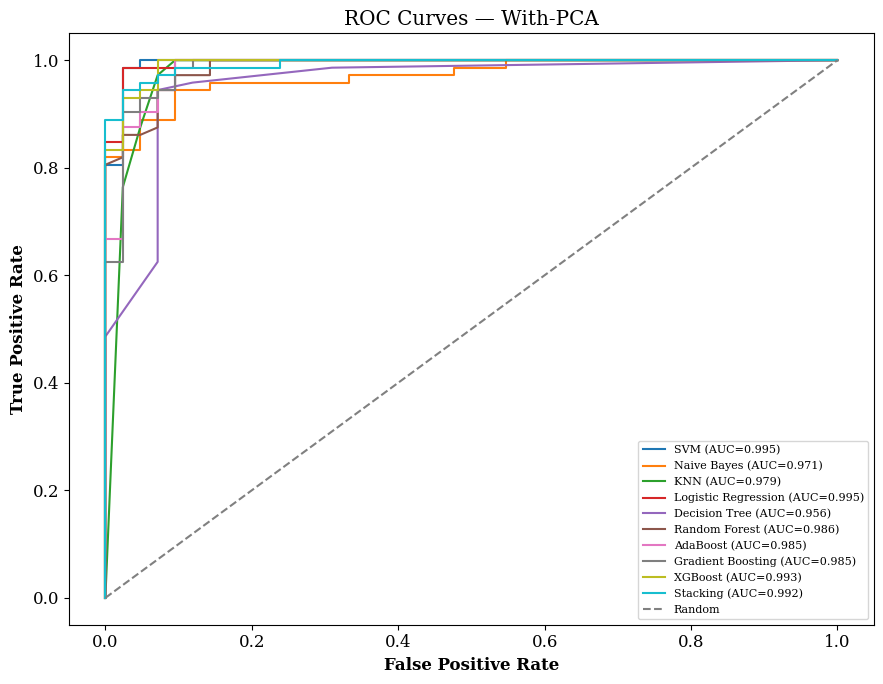

In [15]:
for setting, (Xtr, Xte) in feature_sets.items():
    plt.figure(figsize=(9, 7))
    for model_name, (base_model, param_grid) in model_configs.items():
        grid = GridSearchCV(base_model, param_grid, cv=cv_strategy, scoring="accuracy", n_jobs=-1)
        grid.fit(Xtr, y_train)
        best_model = grid.best_estimator_
        if hasattr(best_model, "predict_proba"):
            y_prob = best_model.predict_proba(Xte)[:, 1]
            fpr, tpr, _ = roc_curve(y_test, y_prob)
            auc = roc_auc_score(y_test, y_prob)
            plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curves — {setting}")
    plt.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()

Best No-PCA model: SVM (Accuracy = 0.9825)
Best With-PCA model: Logistic Regression (Accuracy = 0.9737)


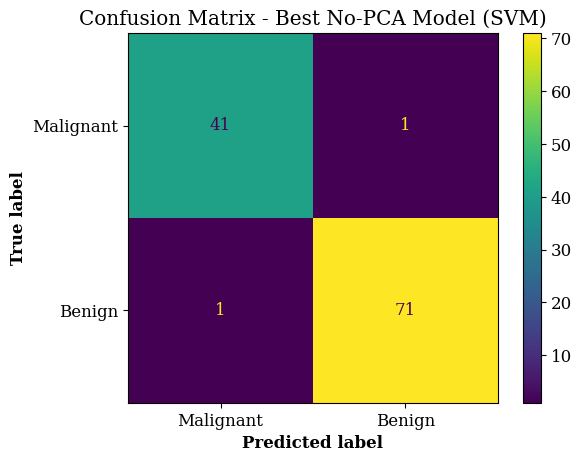

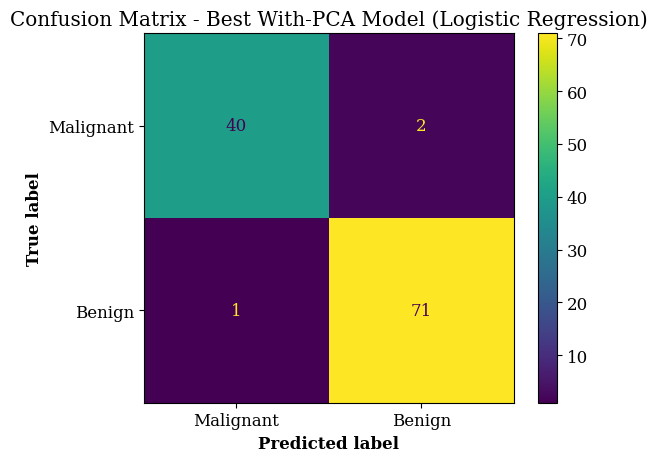

In [16]:
best_no_pca = results_df[results_df["Setting"] == "No-PCA"].sort_values("Accuracy", ascending=False).iloc[0]
best_with_pca = results_df[results_df["Setting"] == "With-PCA"].sort_values("Accuracy", ascending=False).iloc[0]

print(f"Best No-PCA model: {best_no_pca['Model']} (Accuracy = {best_no_pca['Accuracy']:.4f})")
print(f"Best With-PCA model: {best_with_pca['Model']} (Accuracy = {best_with_pca['Accuracy']:.4f})")

for label, row in [("No-PCA", best_no_pca), ("With-PCA", best_with_pca)]:
    model_name = row["Model"]
    Xtr, Xte = feature_sets[label]
    base_model, param_grid = model_configs[model_name]
    grid = GridSearchCV(base_model, param_grid, cv=cv_strategy, scoring="accuracy", n_jobs=-1)
    grid.fit(Xtr, y_train)
    y_pred = grid.best_estimator_.predict(Xte)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Malignant", "Benign"])
    plt.title(f"Confusion Matrix - Best {label} Model ({model_name})")
    plt.show()

## Conclusion
Ten classifiers were trained and tuned with 5-fold cross-validation, once on the standardized original 30 features and once on features reduced via PCA (95% variance retained). The comparison tables and charts above show that PCA's benefit is not uniform across model families — it tends to help distance-based and linear models more than tree-based ensembles, at the cost of a small amount of information loss from the discarded variance. The right choice between the two depends on which model family is ultimately deployed and whether training/inference speed on the reduced feature set matters more than the last percentage point of accuracy.